# VC · Práctica 5 — 05. Comparativa Final en Test (FER-2013)

Este notebook **no entrena modelos**: carga los artefactos entrenados desde `outputs_p5/models/` (modelos clásicos, `CNNFer`, `ResNet18`, ensamble `CNN + ResNet18` y `DeepFace`) mediante `fer_lib/` para evaluarlos sobre `test/` completo y sobre la muestra estratificada común (`n = 1.000`).

- **Dos escenarios de evaluación:**
  1. *Test completo* (7.178 imágenes): todos los modelos salvo DeepFace.
  2. *Muestra común* (1.000 imágenes estratificadas): todos los modelos, incluido DeepFace, sobre exactamente las mismas imágenes.
- **Métricas:** accuracy, F1-macro (la más relevante con clases desbalanceadas) y F1-ponderado, además de los milisegundos por imagen.
- **Salidas:** `resultados_comparativa.csv`, `comparativa_final.png` y las matrices de confusión, en `outputs_p5/`.

## Configuración, rutas y librerías

In [1]:
import sys
from pathlib import Path

P5_ROOT = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents) if (p / "fer_lib").is_dir())
if str(P5_ROOT) not in sys.path:
    sys.path.insert(0, str(P5_ROOT))

import random, time, warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from fer_lib.config import (
    CNN_CKPT,
    CNN_DIR,
    DEEPFACE_N,
    OTHERS_DIR,
    OUT_DIR,
    RESNET18_CKPT,
    SEED,
    TEST_DIR,
    configure_runtime_env,
    load_json,
)
from fer_lib.data import get_common_test_indices, load_split, preparar_features_test
from fer_lib.evaluation import measure_probs, registrar_evaluacion
from fer_lib.models import load_checkpoint

configure_runtime_env()
warnings.filterwarnings("ignore", category=UserWarning)
random.seed(SEED)
np.random.seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
assert TEST_DIR.is_dir(), f"No encuentro test/ en {TEST_DIR.parent}"
assert CNN_CKPT.is_file(), f"No encuentro el checkpoint CNN en {CNN_CKPT}"
assert RESNET18_CKPT.is_file(), f"No encuentro el checkpoint ResNet18 en {RESNET18_CKPT}"
assert OTHERS_DIR.is_dir(), f"No encuentro modelos clásicos/DeepFace en {OTHERS_DIR}"
print(f"Dispositivo: {device} | CNN: {CNN_CKPT.name} | ResNet18: {RESNET18_CKPT.name}")

Dispositivo: cuda | CNN: cnn_fer_torch_seed42.pt | ResNet18: resnet18_fer_torch_seed42.pt


## Carga y exploración del conjunto de test

In [2]:
CLASS_NAMES = load_json(CNN_DIR / "class_names.json")
N_CLASSES = len(CLASS_NAMES)
X_test, y_test, _ = load_split(TEST_DIR, CLASS_NAMES)

df_idx = get_common_test_indices(
    X_test, y_test, n_samples=DEEPFACE_N, seed=SEED, idx_file=OTHERS_DIR / "deepface_test_idx.npy"
)
X_sample, y_sample = X_test[df_idx], y_test[df_idx]
print("Clases:", CLASS_NAMES)
print(f"Test completo: {X_test.shape} | Muestra común: {X_sample.shape}")

test/angry:   0%|          | 0/958 [00:00<?, ?it/s]

test/disgusted:   0%|          | 0/111 [00:00<?, ?it/s]

test/fearful:   0%|          | 0/1024 [00:00<?, ?it/s]

test/happy:   0%|          | 0/1774 [00:00<?, ?it/s]

test/neutral:   0%|          | 0/1233 [00:00<?, ?it/s]

test/sad:   0%|          | 0/1247 [00:00<?, ?it/s]

test/surprised:   0%|          | 0/831 [00:00<?, ?it/s]

Clases: ['angry', 'disgusted', 'fearful', 'happy', 'neutral', 'sad', 'surprised']
Test completo: (7178, 48, 48) | Muestra común: (1000, 48, 48)


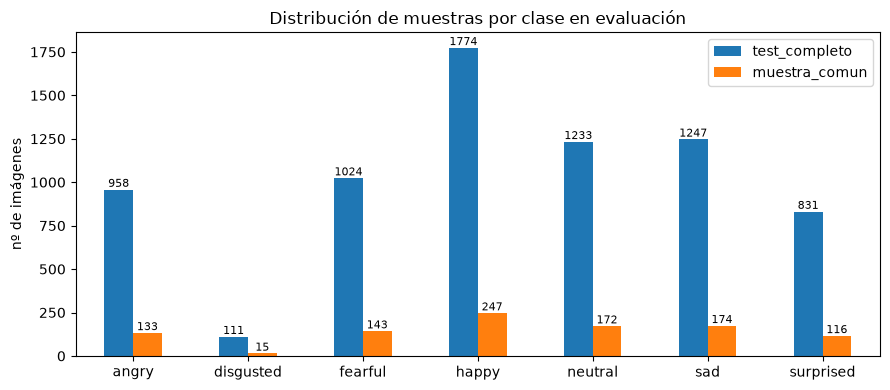

           test_completo  muestra_comun
angry                958            133
disgusted            111             15
fearful             1024            143
happy               1774            247
neutral             1233            172
sad                 1247            174
surprised            831            116


In [3]:
# --- Distribución de muestras en test y muestra común ---
counts = pd.DataFrame({
    "test_completo": np.bincount(y_test, minlength=N_CLASSES),
    "muestra_comun": np.bincount(y_sample, minlength=N_CLASSES),
}, index=CLASS_NAMES)
ax = counts.plot(kind="bar", figsize=(9, 4), rot=0)
for cont in ax.containers:
    ax.bar_label(cont, fontsize=8)
ax.set_title("Distribución de muestras por clase en evaluación")
ax.set_ylabel("nº de imágenes")
plt.tight_layout(); plt.show()
print(counts)

## Evaluación de modelos clásicos cargados

[completo] PCA+KNN (Clásico) -> Acc=0.2912 | F1-macro=0.3089 | F1-w=0.2800 | 0.051 ms/img
[muestra] PCA+KNN (Clásico) -> Acc=0.2790 | F1-macro=0.2892 | F1-w=0.2649 | 0.049 ms/img
[completo] HOG+KNN (Clásico) -> Acc=0.4974 | F1-macro=0.4677 | F1-w=0.4810 | 0.589 ms/img
[muestra] HOG+KNN (Clásico) -> Acc=0.5010 | F1-macro=0.4613 | F1-w=0.4790 | 0.638 ms/img
[completo] LBP+KNN (Clásico) -> Acc=0.2941 | F1-macro=0.2867 | F1-w=0.2812 | 0.400 ms/img
[muestra] LBP+KNN (Clásico) -> Acc=0.2850 | F1-macro=0.2398 | F1-w=0.2687 | 0.406 ms/img
[completo] PCA+SVM (Clásico) -> Acc=0.4184 | F1-macro=0.3842 | F1-w=0.4105 | 1.225 ms/img
[muestra] PCA+SVM (Clásico) -> Acc=0.4090 | F1-macro=0.3529 | F1-w=0.4004 | 1.222 ms/img
[completo] HOG+SVM (Clásico) -> Acc=0.5102 | F1-macro=0.4794 | F1-w=0.5047 | 4.821 ms/img
              precision    recall  f1-score   support

       angry      0.386     0.381     0.383       958
   disgusted      0.711     0.288     0.410       111
     fearful      0.391     0.3

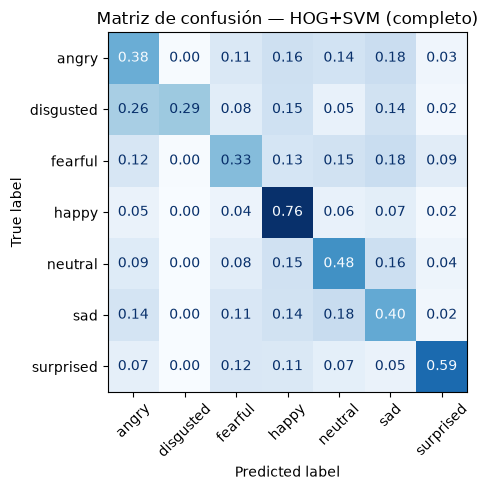

[muestra] HOG+SVM (Clásico) -> Acc=0.4960 | F1-macro=0.4316 | F1-w=0.4872 | 4.873 ms/img
[completo] LBP+SVM (Clásico) -> Acc=0.2405 | F1-macro=0.2226 | F1-w=0.2435 | 0.697 ms/img
[muestra] LBP+SVM (Clásico) -> Acc=0.2190 | F1-macro=0.1987 | F1-w=0.2211 | 0.698 ms/img
[completo] Stacked (Clásico) -> Acc=0.4671 | F1-macro=0.4183 | F1-w=0.4664 | 3.646 ms/img
[muestra] Stacked (Clásico) -> Acc=0.4650 | F1-macro=0.4195 | F1-w=0.4641 | 3.716 ms/img


In [4]:
resultados = []

pca = joblib.load(OTHERS_DIR / "pca_transformer.joblib")
feats_full = preparar_features_test(X_test, pca)
feats_sample = preparar_features_test(X_sample, pca)

classic_order = [
    "pca_knn.joblib", "hog_knn.joblib", "lbp_knn.joblib",
    "pca_svm.joblib", "hog_svm.joblib", "lbp_svm.joblib", "stacked.joblib",
]

for fname in classic_order:
    fpath = OTHERS_DIR / fname
    if not fpath.is_file():
        continue
    bundle = joblib.load(fpath)
    clf_pipe, ftype, mname = bundle["model"], bundle["feat_type"], bundle["name"]

    Xf, tf_ext = feats_full[ftype]
    t0 = time.perf_counter()
    preds_full = clf_pipe.predict(Xf)
    ms_full = ((tf_ext + (time.perf_counter() - t0)) / len(y_test)) * 1000.0
    registrar_evaluacion(
        resultados, mname, "Clásico", "completo", y_test, preds_full, ms_full,
        CLASS_NAMES, mostrar_reporte=(mname == "HOG+SVM"), guardar_cm=(mname == "HOG+SVM"), out_dir=OUT_DIR
    )

    Xs, ts_ext = feats_sample[ftype]
    t0 = time.perf_counter()
    preds_samp = clf_pipe.predict(Xs)
    ms_samp = ((ts_ext + (time.perf_counter() - t0)) / len(y_sample)) * 1000.0
    registrar_evaluacion(
        resultados, mname, "Clásico", "muestra", y_sample, preds_samp, ms_samp,
        CLASS_NAMES, mostrar_reporte=False, guardar_cm=False, out_dir=OUT_DIR
    )

## Evaluación de la CNN cargada (`v1_CNN_torch`)

Configuración CNN cargada: {'framework': 'pytorch', 'seed': 42, 'balance_train': False, 'per_class_cap': None, 'filters': [48, 96, 192, 384], 'dropouts': [0.05, 0.1, 0.15, 0.2], 'head_units': 256, 'head_dropout': 0.4, 'aug_rotation_deg': 10.8, 'aug_zoom': 0.1, 'learning_rate': 0.001, 'weight_decay': 0.0001, 'label_smoothing': 0.1, 'epochs_run': 71, 'best_epoch': 59, 'val_loss': 1.2233392629254698, 'val_accuracy': 0.6896551724137931, 'val_f1_macro': 0.6723677445752182, 'train_minutes': 10.2}
[completo] CNN (CNN propia) -> Acc=0.6941 | F1-macro=0.6746 | F1-w=0.6902 | 0.164 ms/img
              precision    recall  f1-score   support

       angry      0.631     0.637     0.634       958
   disgusted      0.627     0.712     0.667       111
     fearful      0.550     0.486     0.516      1024
       happy      0.871     0.888     0.879      1774
     neutral      0.625     0.715     0.667      1233
         sad      0.611     0.518     0.561      1247
   surprised      0.766     0.834   

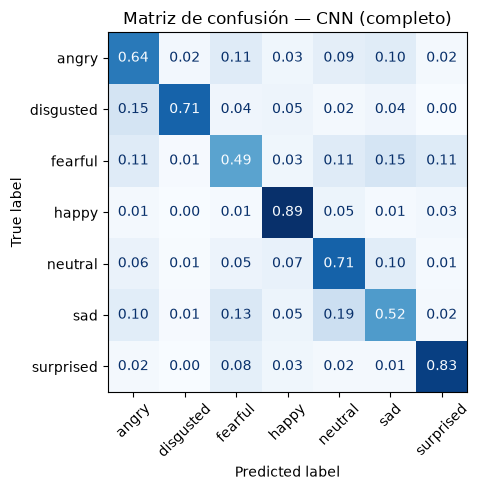

[muestra] CNN (CNN propia) -> Acc=0.7070 | F1-macro=0.6882 | F1-w=0.7045 | 1.643 ms/img
              precision    recall  f1-score   support

       angry      0.639     0.639     0.639       133
   disgusted      0.667     0.667     0.667        15
     fearful      0.634     0.497     0.557       143
       happy      0.898     0.858     0.878       247
     neutral      0.604     0.727     0.660       172
         sad      0.635     0.580     0.607       174
   surprised      0.746     0.888     0.811       116

    accuracy                          0.707      1000
   macro avg      0.689     0.694     0.688      1000
weighted avg      0.709     0.707     0.705      1000



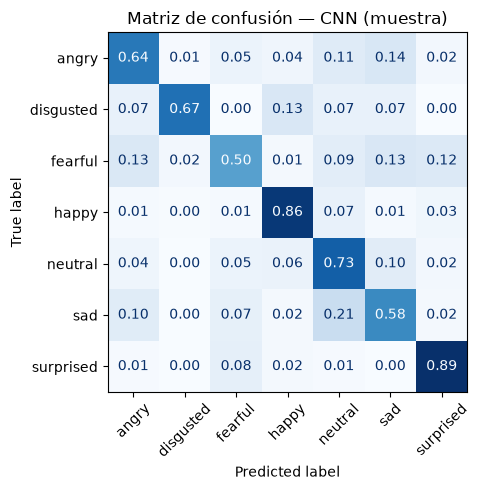

{'modelo': 'CNN',
 'familia': 'CNN propia',
 'conjunto': 'muestra',
 'n': 1000,
 'accuracy': 0.707,
 'f1_macro': 0.6882478260756981,
 'f1_weighted': 0.7045442839858931,
 'ms_img': 1.6434319760010112}

In [5]:
cnn, _, _ = load_checkpoint(CNN_CKPT, device=device)
cnn_cfg_path = CNN_DIR / f"cnn_fer_torch_seed{SEED}_config.json"
if cnn_cfg_path.is_file():
    print("Configuración CNN cargada:", load_json(cnn_cfg_path))

p_test_cnn, ms_cnn_full = measure_probs(cnn, X_test, device=device, batch_size=256, use_tta=True)
registrar_evaluacion(
    resultados, "CNN", "CNN propia", "completo", y_test, p_test_cnn.argmax(1),
    ms_cnn_full, CLASS_NAMES, mostrar_reporte=True, guardar_cm=True, out_dir=OUT_DIR
)

p_samp_cnn, ms_cnn_samp = measure_probs(cnn, X_sample, device=device, batch_size=1, use_tta=True)
registrar_evaluacion(
    resultados, "CNN", "CNN propia", "muestra", y_sample, p_samp_cnn.argmax(1),
    ms_cnn_samp, CLASS_NAMES, mostrar_reporte=True, guardar_cm=True, out_dir=OUT_DIR
)

## Evaluación de ResNet-18 y ensamble `CNN + ResNet18`

El ensamble promedia con igual peso las probabilidades predichas por `CNNFer` y `ResNet-18` (ambos con TTA horizontal). Todas las métricas y tiempos se calculan dinámicamente en la tabla final.

[completo] ResNet18 (Transfer Learning) -> Acc=0.6847 | F1-macro=0.6606 | F1-w=0.6807 | 0.243 ms/img
              precision    recall  f1-score   support

       angry      0.589     0.633     0.610       958
   disgusted      0.581     0.676     0.625       111
     fearful      0.561     0.497     0.527      1024
       happy      0.848     0.911     0.878      1774
     neutral      0.627     0.662     0.644      1233
         sad      0.588     0.508     0.545      1247
   surprised      0.796     0.794     0.795       831

    accuracy                          0.685      7178
   macro avg      0.656     0.669     0.661      7178
weighted avg      0.679     0.685     0.681      7178



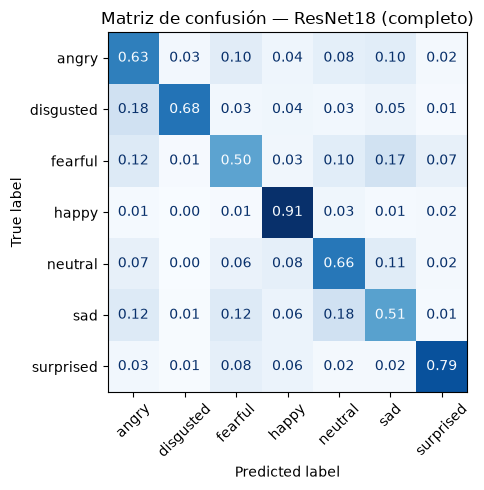

[muestra] ResNet18 (Transfer Learning) -> Acc=0.6740 | F1-macro=0.6488 | F1-w=0.6713 | 3.172 ms/img
              precision    recall  f1-score   support

       angry      0.545     0.632     0.585       133
   disgusted      0.667     0.533     0.593        15
     fearful      0.612     0.517     0.561       143
       happy      0.855     0.883     0.869       247
     neutral      0.588     0.640     0.613       172
         sad      0.580     0.500     0.537       174
   surprised      0.769     0.802     0.785       116

    accuracy                          0.674      1000
   macro avg      0.659     0.644     0.649      1000
weighted avg      0.672     0.674     0.671      1000



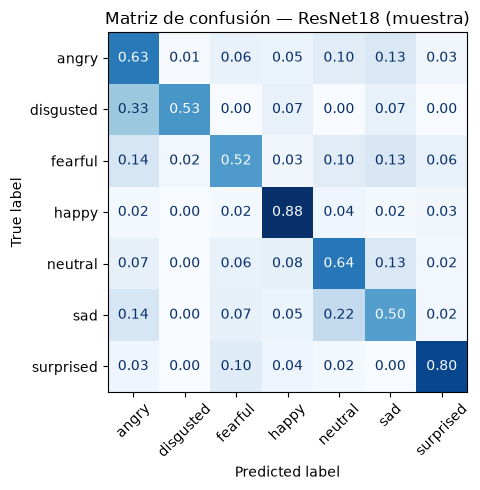

[completo] CNN + ResNet18 (Ensamble) -> Acc=0.7067 | F1-macro=0.6867 | F1-w=0.7030 | 0.407 ms/img
              precision    recall  f1-score   support

       angry      0.635     0.652     0.643       958
   disgusted      0.632     0.712     0.669       111
     fearful      0.589     0.509     0.546      1024
       happy      0.864     0.905     0.884      1774
     neutral      0.642     0.713     0.676      1233
         sad      0.620     0.544     0.579      1247
   surprised      0.795     0.824     0.809       831

    accuracy                          0.707      7178
   macro avg      0.682     0.694     0.687      7178
weighted avg      0.702     0.707     0.703      7178



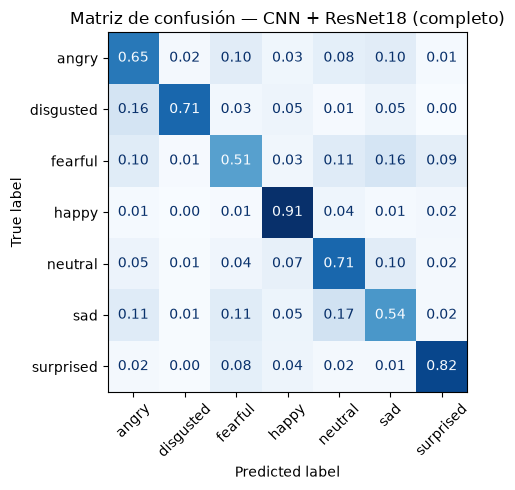

[muestra] CNN + ResNet18 (Ensamble) -> Acc=0.7060 | F1-macro=0.6851 | F1-w=0.7039 | 4.816 ms/img
              precision    recall  f1-score   support

       angry      0.631     0.669     0.650       133
   disgusted      0.625     0.667     0.645        15
     fearful      0.623     0.531     0.574       143
       happy      0.889     0.879     0.884       247
     neutral      0.611     0.703     0.654       172
         sad      0.625     0.546     0.583       174
   surprised      0.772     0.845     0.807       116

    accuracy                          0.706      1000
   macro avg      0.682     0.691     0.685      1000
weighted avg      0.705     0.706     0.704      1000



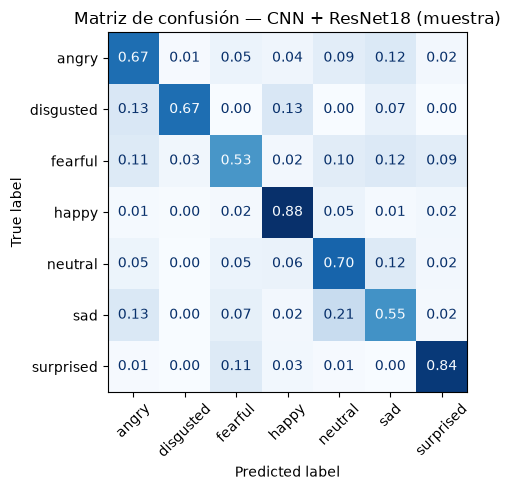

{'modelo': 'CNN + ResNet18',
 'familia': 'Ensamble',
 'conjunto': 'muestra',
 'n': 1000,
 'accuracy': 0.706,
 'f1_macro': 0.685107445932604,
 'f1_weighted': 0.7038995125490483,
 'ms_img': 4.815854119000505}

In [6]:
resnet, res_classes, _ = load_checkpoint(RESNET18_CKPT, device=device)
assert res_classes == CLASS_NAMES, f"Clases de ResNet18 no coinciden: {res_classes}"

p_test_resnet, ms_resnet_full = measure_probs(resnet, X_test, device=device, batch_size=256, use_tta=True)
registrar_evaluacion(
    resultados, "ResNet18", "Transfer Learning", "completo", y_test, p_test_resnet.argmax(1),
    ms_resnet_full, CLASS_NAMES, mostrar_reporte=True, guardar_cm=True, out_dir=OUT_DIR
)

p_samp_resnet, ms_resnet_samp = measure_probs(resnet, X_sample, device=device, batch_size=1, use_tta=True)
registrar_evaluacion(
    resultados, "ResNet18", "Transfer Learning", "muestra", y_sample, p_samp_resnet.argmax(1),
    ms_resnet_samp, CLASS_NAMES, mostrar_reporte=True, guardar_cm=True, out_dir=OUT_DIR
)

p_test_ensemble = 0.5 * (p_test_cnn + p_test_resnet)
p_samp_ensemble = 0.5 * (p_samp_cnn + p_samp_resnet)
registrar_evaluacion(
    resultados, "CNN + ResNet18", "Ensamble", "completo", y_test, p_test_ensemble.argmax(1),
    ms_cnn_full + ms_resnet_full, CLASS_NAMES, mostrar_reporte=True, guardar_cm=True, out_dir=OUT_DIR
)
registrar_evaluacion(
    resultados, "CNN + ResNet18", "Ensamble", "muestra", y_sample, p_samp_ensemble.argmax(1),
    ms_cnn_samp + ms_resnet_samp, CLASS_NAMES, mostrar_reporte=True, guardar_cm=True, out_dir=OUT_DIR
)

## Evaluación de DeepFace cargado (`v1_otros`)

[muestra] DeepFace (DeepFace) -> Acc=0.5590 | F1-macro=0.5455 | F1-w=0.5597 | 5.029 ms/img
              precision    recall  f1-score   support

       angry      0.500     0.376     0.429       133
   disgusted      0.571     0.533     0.552        15
     fearful      0.444     0.441     0.442       143
       happy      0.777     0.761     0.769       247
     neutral      0.432     0.552     0.485       172
         sad      0.437     0.437     0.437       174
   surprised      0.731     0.681     0.705       116

    accuracy                          0.559      1000
   macro avg      0.556     0.540     0.546      1000
weighted avg      0.566     0.559     0.560      1000



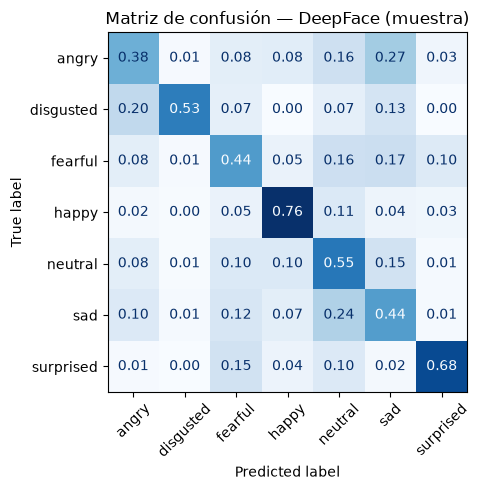

{'modelo': 'DeepFace',
 'familia': 'DeepFace',
 'conjunto': 'muestra',
 'n': 1000,
 'accuracy': 0.559,
 'f1_macro': 0.5455375336382773,
 'f1_weighted': 0.5596895256636744,
 'ms_img': 5.028574871000274}

In [7]:
df_preds = np.load(OTHERS_DIR / "deepface_preds.npy")
df_meta = load_json(OTHERS_DIR / "deepface_meta.json")

registrar_evaluacion(
    resultados, "DeepFace", "DeepFace", "muestra",
    y_sample, df_preds, df_meta["ms_img"],
    CLASS_NAMES, mostrar_reporte=True, guardar_cm=True, out_dir=OUT_DIR
)

## Comparativa final

=== TABLA 1: Evaluación en TEST COMPLETO (n = 7.178) ===


,modelo,familia,conjunto,n,accuracy,f1_macro,f1_weighted,ms_img
18,CNN + ResNet18,Ensamble,completo,7178,0.706743,0.686730,0.703016,0.407336
14,CNN,CNN propia,completo,7178,0.694065,0.674578,0.690244,0.164203
16,ResNet18,Transfer Learning,completo,7178,0.684731,0.660621,0.680665,0.243133
8,HOG+SVM,Clásico,completo,7178,0.510170,0.479354,0.504746,4.820570
2,HOG+KNN,Clásico,completo,7178,0.497353,0.467670,0.481009,0.588863
12,Stacked,Clásico,completo,7178,0.467122,0.418298,0.466444,3.645726
6,PCA+SVM,Clásico,completo,7178,0.418362,0.384207,0.410523,1.225268
4,LBP+KNN,Clásico,completo,7178,0.294093,0.286670,0.281158,0.400035
0,PCA+KNN,Clásico,completo,7178,0.291167,0.308891,0.280042,0.051122
10,LBP+SVM,Clásico,completo,7178,0.240457,0.222553,0.243503,0.697055


=== TABLA 2: Comparativa directa en MUESTRA COMÚN (n = 1.000) ===


,modelo,familia,conjunto,n,accuracy,f1_macro,f1_weighted,ms_img
15,CNN,CNN propia,muestra,1000,0.707,0.688248,0.704544,1.643432
19,CNN + ResNet18,Ensamble,muestra,1000,0.706,0.685107,0.703900,4.815854
17,ResNet18,Transfer Learning,muestra,1000,0.674,0.648822,0.671321,3.172422
20,DeepFace,DeepFace,muestra,1000,0.559,0.545538,0.559690,5.028575
3,HOG+KNN,Clásico,muestra,1000,0.501,0.461268,0.479016,0.638027
9,HOG+SVM,Clásico,muestra,1000,0.496,0.431599,0.487249,4.872831
13,Stacked,Clásico,muestra,1000,0.465,0.419471,0.464080,3.716068
7,PCA+SVM,Clásico,muestra,1000,0.409,0.352887,0.400402,1.222039
5,LBP+KNN,Clásico,muestra,1000,0.285,0.239782,0.268730,0.406428
1,PCA+KNN,Clásico,muestra,1000,0.279,0.289211,0.264907,0.049496


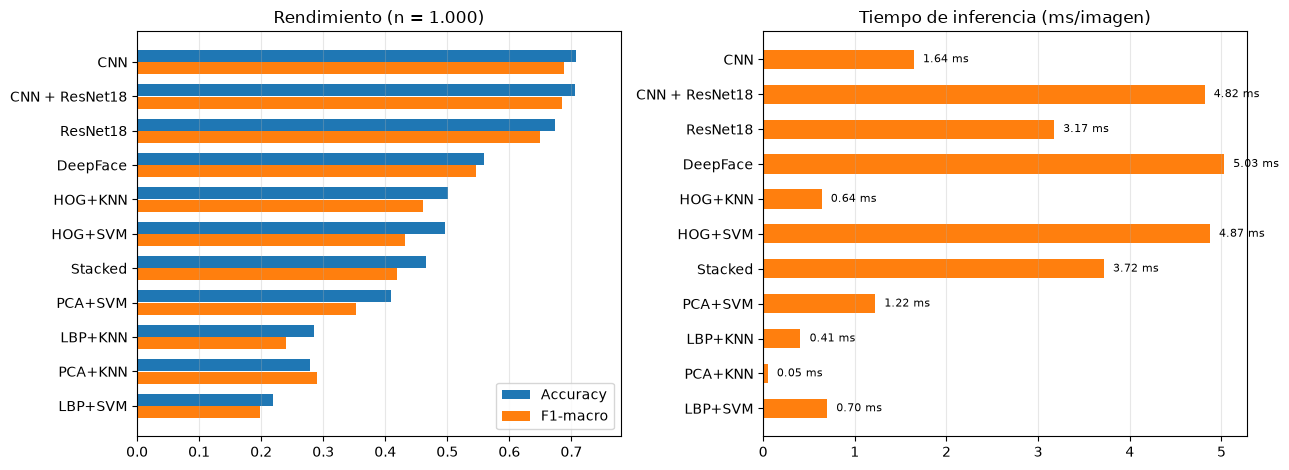

In [8]:
df_res = pd.DataFrame(resultados)
df_res.to_csv(OUT_DIR / "resultados_comparativa.csv", index=False)

print("=== TABLA 1: Evaluación en TEST COMPLETO (n = 7.178) ===")
display(df_res[df_res["conjunto"] == "completo"].sort_values("accuracy", ascending=False))

print("=== TABLA 2: Comparativa directa en MUESTRA COMÚN (n = 1.000) ===")
df_muestra = df_res[df_res["conjunto"] == "muestra"].sort_values("accuracy", ascending=False)
display(df_muestra)

# Gráfico resumen de precisión vs velocidad en la muestra común
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
m_plot = df_muestra.sort_values("accuracy", ascending=True)
y_pos = np.arange(len(m_plot))

axes[0].barh(y_pos + 0.18, m_plot["accuracy"], height=0.35, label="Accuracy")
axes[0].barh(y_pos - 0.18, m_plot["f1_macro"], height=0.35, label="F1-macro")
axes[0].set_yticks(y_pos); axes[0].set_yticklabels(m_plot["modelo"])
axes[0].set_xlim(0, 0.78); axes[0].set_title("Rendimiento (n = 1.000)")
axes[0].grid(axis="x", alpha=0.3); axes[0].legend()

axes[1].barh(y_pos, m_plot["ms_img"], height=0.55, color="tab:orange")
axes[1].set_yticks(y_pos); axes[1].set_yticklabels(m_plot["modelo"])
axes[1].set_title("Tiempo de inferencia (ms/imagen)")
axes[1].grid(axis="x", alpha=0.3)
for i, v in enumerate(m_plot["ms_img"]):
    axes[1].text(v + 0.1, i, f"{v:.2f} ms", va="center", fontsize=8)

plt.tight_layout()
fig.savefig(OUT_DIR / "comparativa_final.png", dpi=150)
plt.show()

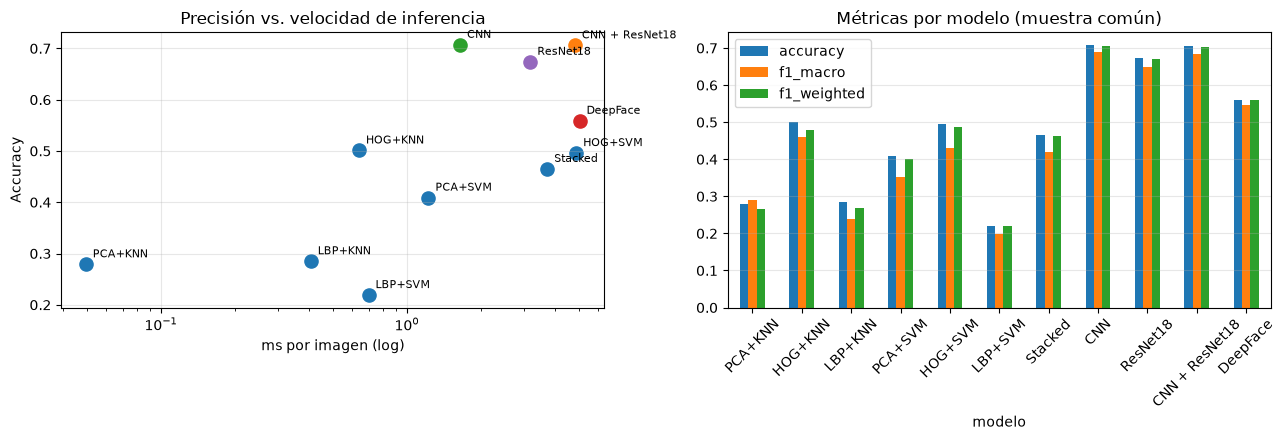

In [9]:
# --- Precisión vs. velocidad (muestra común) ---
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
colors = {"Clásico": "tab:blue", "CNN propia": "tab:green", "DeepFace": "tab:red"}
df_sample = df_res[df_res["conjunto"] == "muestra"].copy()

colors = {
    "Clásico": "tab:blue",
    "CNN propia": "tab:green",
    "Transfer Learning": "tab:purple",
    "Ensamble": "tab:orange",
    "DeepFace": "tab:red",
}

for _, r in df_sample.iterrows():
    ax[0].scatter(
        r["ms_img"],
        r["accuracy"],
        s=90,
        color=colors.get(r["familia"], "tab:gray"),
    )
    ax[0].annotate(
        r["modelo"],
        (r["ms_img"], r["accuracy"]),
        textcoords="offset points",
        xytext=(5, 5),
        fontsize=8,
    )

ax[0].set_xscale("log")
ax[0].set_xlabel("ms por imagen (log)")
ax[0].set_ylabel("Accuracy")
ax[0].set_title("Precisión vs. velocidad de inferencia")
ax[0].grid(alpha=0.3)

df_sample.set_index("modelo")[["accuracy", "f1_macro", "f1_weighted"]].plot(
    kind="bar", ax=ax[1], rot=45
)
ax[1].set_title("Métricas por modelo (muestra común)")
ax[1].grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.show()